In [54]:
import numpy as np
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date
from scipy.stats import norm

In [55]:
# Assets for the portfolio

tickers = [
    "AAPL",  # Apple
    "NVDA",  # Nvidia
    "MSFT",  # Microsoft
    "JPM",   # JPMorgan Chase
    "BAC",   # Bank of America
    "SHEL",  # Shell
    "XOM",   # Exxon Mobil
    "GLD",   # SPDR Gold Shares
    "BZ=F",  # Brent crude oil futures
    "NG=F"   # Natural gas (Henry Hub) futures
]


# Time period
START_DATE = "2010-01-01"
END_DATE = date.today().strftime("%Y-%m-%d")

In [56]:
# Getting data from Yahoo Finance

data = yf.download(
    tickers,
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    auto_adjust=True,
    progress=False
)

In [57]:
data

Price            Close                                                 \
Ticker            AAPL        BAC        BZ=F         GLD         JPM   
Date                                                                    
2010-01-04    6.400960  11.977124   80.120003  109.800003   28.012621   
2010-01-05    6.412027  12.366439   80.589996  109.699997   28.555229   
2010-01-06    6.310035  12.511477   81.889999  111.510002   28.712126   
2010-01-07    6.298369  12.923688   81.510002  110.820000   29.280870   
2010-01-08    6.340243  12.809183   81.370003  111.370003   29.208967   
...                ...        ...         ...         ...         ...   
2026-10-05  332.890015  54.000000  100.320000  379.549988  330.730011   
2026-10-06  333.630005  54.090000  100.580002  382.269989  331.279999   
2026-10-07  336.670013  53.520000  100.199997  375.880005  329.579987   
2026-10-08  340.420013  53.610001  104.279999  378.619995  331.420013   
2026-10-09  336.640015  54.320000  104.720001  384.579987  332.989990   

Price                                                              ...  \
Ticker            MSFT   NG=F        NVDA        SHEL         XOM  ...   
Date                                                               ...   
2010-01-04   22.984234  5.884    0.422817   26.799496   37.136814  ...   
2010-01-05   22.991661  5.637    0.428992   26.829582   37.281811  ...   
2010-01-06   22.850567  6.009    0.431736   26.610369   37.604023  ...   
2010-01-07   22.612921  5.806    0.423275   26.481424   37.485897  ...   
2010-01-08   22.768875  5.749    0.424189   26.442747   37.335522  ...   
...                ...    ...         ...         ...         ...  ...   
2026-10-05  525.179993  3.066  238.899994   96.519997  164.000000  ...   
2026-10-06  529.299988  3.114  239.240005   97.620003  164.479996  ...   
2026-10-07  529.760010  3.203  237.470001   96.849998  164.050003  ...   
2026-10-08  522.609985  3.168  230.479996  100.199997  168.500000  ...   
2026-10-09  535.070007  3.220  229.279999  100.180000  168.940002  ...   

Price            Volume                                                \
Ticker             AAPL          BAC     BZ=F         GLD         JPM   
Date                                                                    
2010-01-04  493729600.0  180845200.0     97.0  16224100.0  35460500.0   
2010-01-05  601904800.0  209521300.0     97.0  14213100.0  41208300.0   
2010-01-06  552160000.0  205257900.0      7.0  24981900.0  27729000.0   
2010-01-07  477131200.0  320868400.0      7.0  13609800.0  44864700.0   
2010-01-08  447610800.0  220104700.0      7.0  15894600.0  33110100.0   
...                 ...          ...      ...         ...         ...   
2026-10-05   34400900.0   34994400.0  39826.0   4289400.0   5346100.0   
2026-10-06   30449000.0   25370300.0  43157.0   7506100.0   6286800.0   
2026-10-07   34147900.0   30913500.0  47830.0   7216600.0   7003000.0   
2026-10-08   35332400.0   59809500.0  47377.0   9706600.0   8060800.0   
2026-10-09   37855000.0   28737700.0  47377.0   7467200.0   5052000.0   

Price                                                                 
Ticker            MSFT      NG=F         NVDA       SHEL         XOM  
Date                                                                  
2010-01-04  38409100.0   78858.0  800204000.0  1643003.0  27809100.0  
2010-01-05  49749600.0   99492.0  728648000.0  1718458.0  30174700.0  
2010-01-06  58182400.0  140611.0  649168000.0  3040554.0  35044700.0  
2010-01-07  50559700.0  135113.0  547792000.0  1033089.0  27192100.0  
2010-01-08  51197400.0  101153.0  478168000.0  1438017.0  24891800.0  
...                ...       ...          ...        ...         ...  
2026-10-05  26604800.0  159487.0  127171500.0  6929672.0  12475500.0  
2026-10-06  21107500.0  157738.0  101701900.0  8159672.0   9285400.0  
2026-10-07  16790200.0  265951.0   81772400.0  4926866.0   9516200.0  
2026-10-08  20228700.0  282250.0  118697400.0  9098990.0  1328810

In [58]:
# We only keep the Close values and we check dates order
data = data["Close"].sort_index()
data.tail()

Ticker,AAPL,BAC,BZ=F,GLD,JPM,MSFT,NG=F,NVDA,SHEL,XOM
Date,,,,,,,,,,
2026-10-05,332.890015,54.000000,100.320000,379.549988,330.730011,525.179993,3.066,238.899994,96.519997,164.000000
2026-10-06,333.630005,54.090000,100.580002,382.269989,331.279999,529.299988,3.114,239.240005,97.620003,164.479996
2026-10-07,336.670013,53.520000,100.199997,375.880005,329.579987,529.760010,3.203,237.470001,96.849998,164.050003
2026-10-08,340.420013,53.610001,104.279999,378.619995,331.420013,522.609985,3.168,230.479996,100.199997,168.500000
2026-10-09,336.640015,54.320000,104.720001,384.579987,332.989990,535.070007,3.220,229.279999,100.180000,168.940002


In [59]:
# Renaming the columns

data.rename(columns={
    
    "SPY": "S&P 500",
    "AAPL": "Apple",
    "NVDA": "Nvidia",
    "MSFT": "Microsoft",
    "JPM": "JPMorgan",
    "BAC": "Bank of America",
    "SHEL": "Shell",
    "XOM": "Exxon Mobil",
    "GLD": "Gold",
    "BZ=F": "Oil",
    "NG=F": "Gas"
    
},inplace = True)

In [60]:
data.head()

Ticker,Apple,Bank of America,Oil,Gold,JPMorgan,Microsoft,Gas,Nvidia,Shell,Exxon Mobil
Date,,,,,,,,,,
2010-01-04,6.400960,11.977124,80.120003,109.800003,28.012621,22.984234,5.884,0.422817,26.799496,37.136814
2010-01-05,6.412027,12.366439,80.589996,109.699997,28.555229,22.991661,5.637,0.428992,26.829582,37.281811
2010-01-06,6.310035,12.511477,81.889999,111.510002,28.712126,22.850567,6.009,0.431736,26.610369,37.604023
2010-01-07,6.298369,12.923688,81.510002,110.820000,29.280870,22.612921,5.806,0.423275,26.481424,37.485897
2010-01-08,6.340243,12.809183,81.370003,111.370003,29.208967,22.768875,5.749,0.424189,26.442747,37.335522


In [61]:
# Removing NaN values

data.dropna(inplace=True)
data.isna().sum()


Ticker
Apple              0
Bank of America    0
Oil                0
Gold               0
JPMorgan           0
Microsoft          0
Gas                0
Nvidia             0
Shell              0
Exxon Mobil        0
dtype: int64

In [62]:
# Changing columns order

column = ["Nvidia", "Apple", "Microsoft", "JPMorgan", "Bank of America", "Exxon Mobil", "Shell", "Gold", "Oil", "Gas" ]
data = data[column]

In [63]:
data

Ticker,Nvidia,Apple,Microsoft,JPMorgan,Bank of America,Exxon Mobil,Shell,Gold,Oil,Gas
Date,,,,,,,,,,
2010-01-04,0.422817,6.400960,22.984234,28.012621,11.977124,37.136814,26.799496,109.800003,80.120003,5.884
2010-01-05,0.428992,6.412027,22.991661,28.555229,12.366439,37.281811,26.829582,109.699997,80.589996,5.637
2010-01-06,0.431736,6.310035,22.850567,28.712126,12.511477,37.604023,26.610369,111.510002,81.889999,6.009
2010-01-07,0.423275,6.298369,22.612921,29.280870,12.923688,37.485897,26.481424,110.820000,81.510002,5.806
2010-01-08,0.424189,6.340243,22.768875,29.208967,12.809183,37.335522,26.442747,111.370003,81.370003,5.749
...,...,...,...,...,...,...,...,...,...,...
2026-10-05,238.899994,332.890015,525.179993,330.730011,54.000000,164.000000,96.519997,379.549988,100.320000,3.066
2026-10-06,239.240005,333.630005,529.299988,331.279999,54.090000,164.479996,97.620003,382.269989,100.580002,3.114
2026-10-07,237.470001,336.670013,529.760010,329.579987,53.520000,164.050003,96.849998,375.880005,100.199997,3.203


In [64]:
# Calculating asset returns

def returns(row):
    return np.log(row/row.shift(1))

df_returns = data.apply(returns)
df_returns.dropna(inplace=True)
df_returns


Ticker,Nvidia,Apple,Microsoft,JPMorgan,Bank of America,Exxon Mobil,Shell,Gold,Oil,Gas
Date,,,,,,,,,,
2010-01-05,0.014497,0.001727,0.000323,0.019185,0.031988,0.003897,0.001122,-0.000911,0.005849,-0.042885
2010-01-06,0.006376,-0.016034,-0.006156,0.005479,0.011660,0.008605,-0.008204,0.016365,0.016002,0.063906
2010-01-07,-0.019792,-0.001850,-0.010454,0.019615,0.032416,-0.003146,-0.004857,-0.006207,-0.004651,-0.034366
2010-01-08,0.002158,0.006626,0.006873,-0.002459,-0.008900,-0.004020,-0.001462,0.004951,-0.001719,-0.009866
2010-01-11,-0.014115,-0.008860,-0.012801,-0.003363,0.008900,0.011157,0.015484,0.013201,-0.004928,-0.052677
...,...,...,...,...,...,...,...,...,...,...
2026-10-05,0.020938,-0.002400,0.014673,0.000000,0.004640,-0.000061,0.003009,-0.001553,-0.019056,0.010162
2026-10-06,0.001422,0.002220,0.007814,0.001662,0.001665,0.002923,0.011332,0.007141,0.002588,0.015534
2026-10-07,-0.007426,0.009071,0.000869,-0.005145,-0.010594,-0.002618,-0.007919,-0.016857,-0.003785,0.028180


In [65]:
# Calculating the mean daily returns of the assets
mu = df_returns.mean()
mu

Ticker
Nvidia             0.001505
Apple              0.000947
Microsoft          0.000752
JPMorgan           0.000592
Bank of America    0.000361
Exxon Mobil        0.000362
Shell              0.000315
Gold               0.000300
Oil                0.000064
Gas               -0.000144
dtype: float64

In [66]:
# Putting the means in an array
mu = df_returns.mean().values  
mu

array([ 1.50508226e-03,  9.47302457e-04,  7.52471694e-04,  5.91789929e-04,
        3.61437715e-04,  3.62164682e-04,  3.15224839e-04,  2.99663217e-04,
        6.40125719e-05, -1.44120345e-04])

In [67]:
# Covariance matrix
sigma = df_returns.cov()  
sigma

Ticker,Nvidia,Apple,Microsoft,JPMorgan,Bank of America,Exxon Mobil,Shell,Gold,Oil,Gas
Ticker,,,,,,,,,,
Nvidia,0.000810,0.000237,0.000256,0.000181,0.000213,0.000101,0.000129,0.000012,0.000084,0.000043
Apple,0.000237,0.000316,0.000162,0.000120,0.000143,0.000083,0.000093,0.000009,0.000062,0.000015
Microsoft,0.000256,0.000162,0.000271,0.000122,0.000139,0.000075,0.000094,0.000006,0.000059,0.000040
JPMorgan,0.000181,0.000120,0.000122,0.000299,0.000306,0.000142,0.000156,-0.000007,0.000095,0.000019
Bank of America,0.000213,0.000143,0.000139,0.000306,0.000434,0.000163,0.000172,-0.000012,0.000110,0.000021
Exxon Mobil,0.000101,0.000083,0.000075,0.000142,0.000163,0.000251,0.000208,0.000009,0.000194,0.000059
Shell,0.000129,0.000093,0.000094,0.000156,0.000172,0.000208,0.000307,0.000023,0.000212,0.000052
Gold,0.000012,0.000009,0.000006,-0.000007,-0.000012,0.000009,0.000023,0.000113,0.000022,0.000009
Oil,0.000084,0.000062,0.000059,0.000095,0.000110,0.000194,0.000212,0.000022,0.000550,0.000080


In [68]:
# Putting the covariances in an array
sigma = df_returns.cov().values
sigma 

array([[ 8.09584847e-04,  2.36980528e-04,  2.55970170e-04,
         1.80768070e-04,  2.13329743e-04,  1.00813399e-04,
         1.29471608e-04,  1.15506221e-05,  8.44279811e-05,
         4.33016611e-05],
       [ 2.36980528e-04,  3.16037926e-04,  1.61628483e-04,
         1.19797158e-04,  1.42673663e-04,  8.27278562e-05,
         9.27664778e-05,  9.37524929e-06,  6.21466288e-05,
         1.48061962e-05],
       [ 2.55970170e-04,  1.61628483e-04,  2.70755847e-04,
         1.21803896e-04,  1.38820073e-04,  7.47976188e-05,
         9.36745200e-05,  6.27549596e-06,  5.89566014e-05,
         3.98297271e-05],
       [ 1.80768070e-04,  1.19797158e-04,  1.21803896e-04,
         2.99000006e-04,  3.05618777e-04,  1.41624948e-04,
         1.55870756e-04, -6.73797300e-06,  9.52710610e-05,
         1.87476242e-05],
       [ 2.13329743e-04,  1.42673663e-04,  1.38820073e-04,
         3.05618777e-04,  4.33858508e-04,  1.62816989e-04,
         1.72284242e-04, -1.24547514e-05,  1.10107132e-04,
         2.

In [69]:
MC = 10_000 # 10 000 simulations
rng = np.random.default_rng() # generator of numbers 

# We generate 10,000 scenarios following a normal distribution
simulated_returns = rng.multivariate_normal(mean=mu,cov=sigma,size=MC)  

# Matrix 10,000 rows and N = number of assets columns
# for each asset, we have 100,000 return scenarios
simulated_returns

array([[-0.00535311,  0.00857067,  0.00927723, ..., -0.02057214,
         0.00206277, -0.00343624],
       [-0.01915095,  0.01497633,  0.00239559, ...,  0.0169179 ,
         0.00600061,  0.07469119],
       [-0.00124448, -0.00914102,  0.00065713, ..., -0.01487521,
         0.01664732,  0.00793079],
       ...,
       [ 0.04882417,  0.01168635,  0.01368135, ...,  0.02914355,
         0.01194018, -0.01156304],
       [-0.004296  , -0.00129043,  0.00060666, ...,  0.02113287,
        -0.04784934, -0.01672223],
       [-0.00286028, -0.00105975, -0.0042399 , ..., -0.00858496,
        -0.02107261,  0.02777936]], shape=(10000, 10))

In [70]:
# Spot values of the assets

data.iloc[-1]
spot = data.iloc[-1].values
spot 

array([229.27999878, 336.64001465, 535.07000732, 332.98999023,
        54.31999969, 168.94000244, 100.18000031, 384.57998657,
       104.72000122,   3.22000003])

In [71]:
# Potfolio weight and allocation

weight_Nvidia = 0.15
weight_Apple = 0.15
weight_Microsoft = 0.15
weight_JPMorgan = 0.10
weight_Bank_of_America = 0.10
weight_Exxon_Mobil = 0.05
weight_Shell = 0.05
weight_Gold = 0.1
weight_Oil = 0.1 
weight_Gas = 0.05

s = weight_Nvidia + weight_Apple + weight_Microsoft + weight_JPMorgan + weight_Bank_of_America  + weight_Exxon_Mobil + weight_Shell + weight_Gold + weight_Oil + weight_Gas 
print(s)

allocation = [weight_Nvidia, weight_Apple,weight_Microsoft, weight_JPMorgan, weight_Bank_of_America,weight_Exxon_Mobil,weight_Shell, weight_Gold, weight_Oil,weight_Gas ]
allocation = np.array(allocation)
print(allocation)
sum(allocation)

1.0
[0.15 0.15 0.15 0.1  0.1  0.05 0.05 0.1  0.1  0.05]


np.float64(1.0)

In [72]:
# Initial Value of Portfolio in $

money = 1_000_000
cash_per_asset = money * allocation
print(cash_per_asset)

asset_quantities = cash_per_asset / spot
print(asset_quantities)

initial_portfolio_value = np.sum(asset_quantities * spot)
initial_portfolio_value


[150000. 150000. 150000. 100000. 100000.  50000.  50000. 100000. 100000.
  50000.]
[  654.22191556   445.57982852   280.33714831   300.30932741
  1840.94257293   295.96305953   499.10161557   260.02393128
   954.92741438 15527.95017259]


np.float64(1000000.0)

In [73]:
# Simulated prices for each scenario
simulated_price = spot * np.exp(simulated_returns)
simulated_price

array([[228.05591788, 339.5376431 , 540.05707077, ..., 376.74917814,
        104.93623708,   3.20895431],
       [224.93084604, 341.71958802, 536.35334959, ..., 391.14161852,
        105.35027412,   3.46971536],
       [228.99484181, 333.57680191, 535.42173083, ..., 378.90161543,
        106.47789992,   3.2456387 ],
       ...,
       [240.75218521, 340.59718435, 542.44079349, ..., 395.95293241,
        105.9778716 ,   3.18298149],
       [228.2971239 , 336.20588605, 535.3947087 , ..., 392.79374854,
         99.82720993,   3.16660216],
       [228.62512998, 336.28345041, 532.80616546, ..., 381.29251414,
        102.53636546,   3.31070358]], shape=(10000, 10))

In [74]:
# Values of the new portfolios
portfolio_values = simulated_price @ asset_quantities
print(portfolio_values)

# PnL in the 10,000 scenarios
PnL = portfolio_values - initial_portfolio_value
PnL

[1008373.13400391 1007855.23731653  993968.26904132 ... 1013282.05518404
  997689.73116671  992920.59431361]


array([ 8373.13400391,  7855.23731653, -6031.73095868, ...,
       13282.05518404, -2310.26883329, -7079.40568639], shape=(10000,))

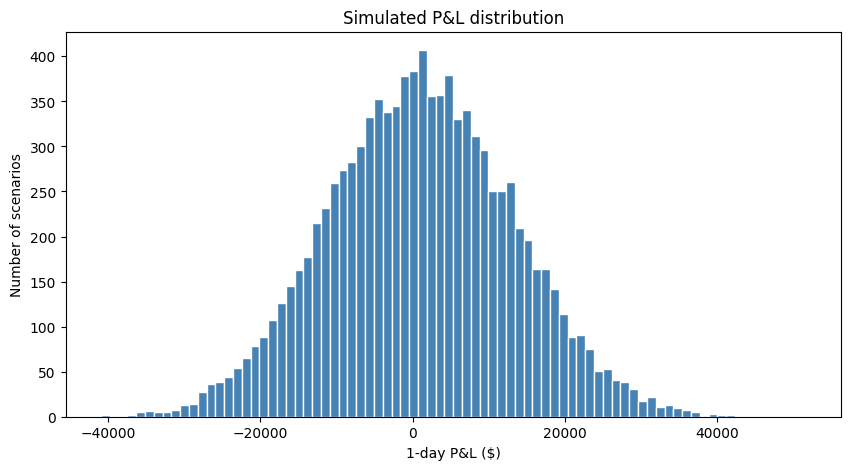

In [75]:
plt.figure(figsize=(10, 5))

plt.hist(PnL, bins=80, color="steelblue", edgecolor="white")

plt.xlabel("1-day P&L ($)")
plt.ylabel("Number of scenarios")
plt.title("Simulated P&L distribution")

plt.show()

In [76]:
# Value at Risk at a 95% confidence level over 1 day
var_95 = np.quantile(PnL, 0.05)
var_95

np.float64(-18880.15766346276)

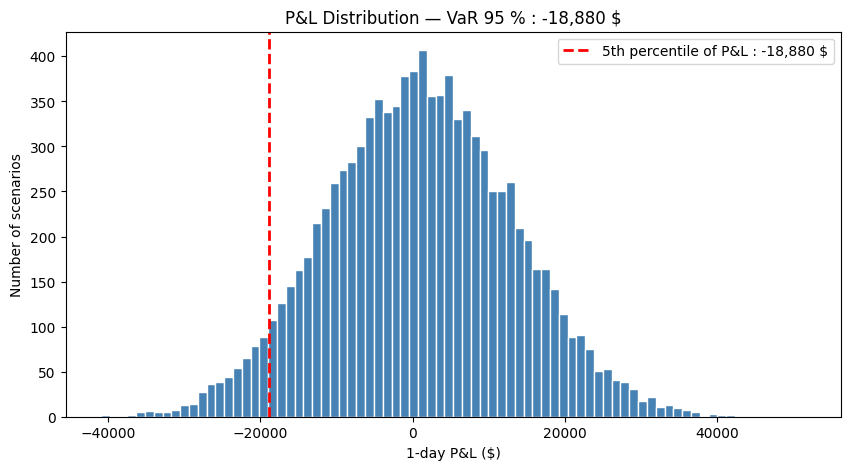

In [77]:
plt.figure(figsize=(10, 5))

plt.hist(PnL, bins=80, color="steelblue", edgecolor="white")

plt.axvline(
    var_95,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"5th percentile of P&L : {var_95:,.0f} $"
)

plt.xlabel("1-day P&L ($)")
plt.ylabel("Number of scenarios")
plt.title(f"P&L Distribution — VaR 95 % : {var_95:,.0f} $")
plt.legend()
plt.show()

# Comparison with a direct calculus

# Portfolio Variance

$$
\sigma_p^2 = w^\top \Sigma w
$$

where:

- $w$ is the vector of asset weights in the portfolio;
- $w^\top$ is the transpose of this vector;
- $\Sigma$ is the covariance matrix of asset returns;
- $\sigma_p^2$ is the variance of portfolio returns.

In [78]:
# mean daily returns of the assets in an array
mu

# asset allocation
allocation

# mean portfolio daily return
mu_p = allocation @ mu
mu_p
print(mu_p)

# daily volatility portfolio 
sigma_p = np.sqrt(allocation @ sigma @ allocation)
sigma_p

0.0006390822637901639


np.float64(0.012179720218173387)

In [79]:
VaR_95 = initial_portfolio_value * (mu_p - norm.ppf(0.05)*sigma_p)
VaR_95

np.float64(20672.939239906842)

In [80]:
# Gap and error
gap = np.abs(-VaR_95-var_95)
gap

error = gap/var_95
print(error*100)

-9.495585833552159
